In [1]:
import json, joblib
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
PROC, FIG, MODELS = Path("../data/processed"), Path("../reports/figures"), Path("../models")
MODELS.mkdir(exist_ok=True)

cfg = json.load(open(PROC/"config.json"))
FEATURES, TARGET = cfg["features"], cfg["target"]

# Sort by time (needed for time-series cross-validation)
train = pd.read_csv(PROC/"train.csv", parse_dates=["DATE_TIME"]).sort_values("DATE_TIME").reset_index(drop=True)
test  = pd.read_csv(PROC/"test.csv",  parse_dates=["DATE_TIME"]).sort_values("DATE_TIME").reset_index(drop=True)

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(X_train.shape, X_test.shape)

(2813, 7) (751, 7)


In [2]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred)}

In [3]:
models = {
    "Mean baseline":     DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost":           XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                      subsample=0.8, random_state=42),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    rows.append({"Model": name, **evaluate(m, X_test, y_test)})

results = pd.DataFrame(rows).sort_values("RMSE").round(3)
results

,Model,MAE,RMSE,R2
1,Linear Regression,37.061,71.705,0.953
2,Random Forest,28.904,72.665,0.951
4,XGBoost,28.515,73.154,0.951
3,Gradient Boosting,29.973,73.247,0.950
0,Mean baseline,293.707,346.875,-0.111


In [4]:
tscv = TimeSeriesSplit(n_splits=5)   # always trains on the past, validates on the future

searches = {
    "Random Forest": RandomizedSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {"n_estimators": [200, 400], "max_depth": [None, 10, 20],
         "min_samples_leaf": [1, 3, 5], "max_features": [0.6, 1.0]},
        n_iter=8, cv=tscv, scoring="neg_mean_absolute_error", random_state=42),
    "XGBoost": RandomizedSearchCV(
        XGBRegressor(random_state=42),
        {"n_estimators": [200, 400], "max_depth": [3, 4, 6],
         "learning_rate": [0.03, 0.05, 0.1], "subsample": [0.7, 1.0]},
        n_iter=8, cv=tscv, scoring="neg_mean_absolute_error", random_state=42),
}

tuned = []
for name, s in searches.items():
    s.fit(X_train, y_train)
    tuned.append({"Model": name + " (tuned)", "CV_MAE": -s.best_score_, **evaluate(s.best_estimator_, X_test, y_test)})
    print(name, s.best_params_)

tuned_df = pd.DataFrame(tuned).round(3)
tuned_df

Random Forest {'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 20}
XGBoost {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05}


,Model,CV_MAE,MAE,RMSE,R2
0,Random Forest (tuned),31.065,27.757,69.316,0.956
1,XGBoost (tuned),32.968,28.726,71.015,0.953


In [5]:
best_name = tuned_df.sort_values("CV_MAE").iloc[0]["Model"].replace(" (tuned)", "")
best_model = searches[best_name].best_estimator_
print("Final model:", best_name)
print(evaluate(best_model, X_test, y_test))

Final model: Random Forest
{'MAE': 27.757020814590987, 'RMSE': np.float64(69.3158179511399), 'R2': 0.9556359282157524}


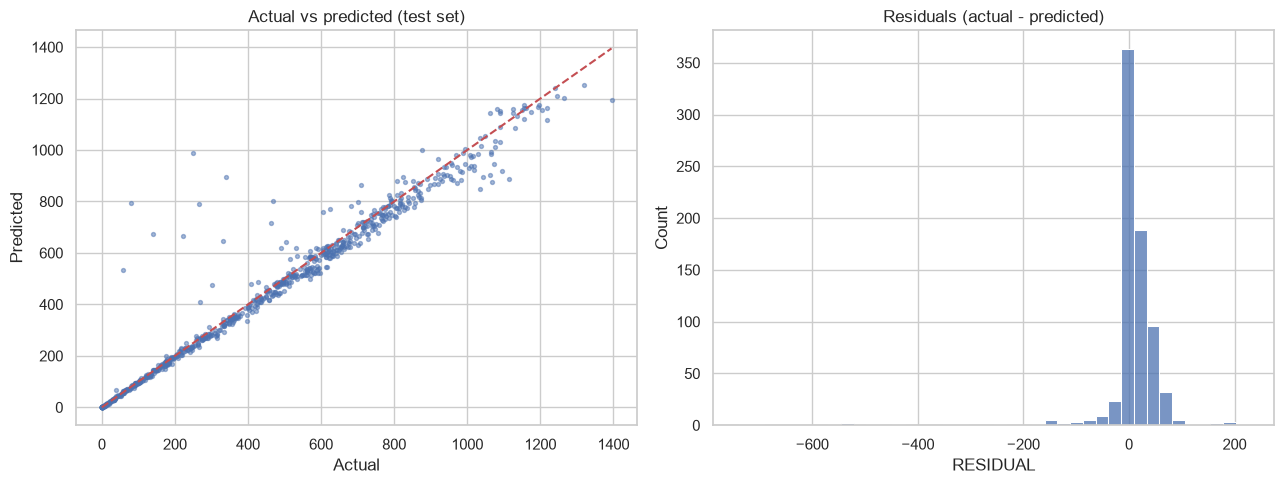

In [6]:
test["PRED"] = best_model.predict(X_test)
test["RESIDUAL"] = test[TARGET] - test["PRED"]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(test[TARGET], test["PRED"], s=8, alpha=.5)
lim = [0, test[TARGET].max()]; ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual vs predicted (test set)")
sns.histplot(test["RESIDUAL"], bins=40, ax=ax[1]); ax[1].set_title("Residuals (actual - predicted)")
plt.tight_layout(); plt.savefig(FIG/"actual_vs_predicted.png", dpi=150); plt.show()

Plant 1: MAE=20.2  R2=0.990
Plant 2: MAE=35.0  R2=0.908


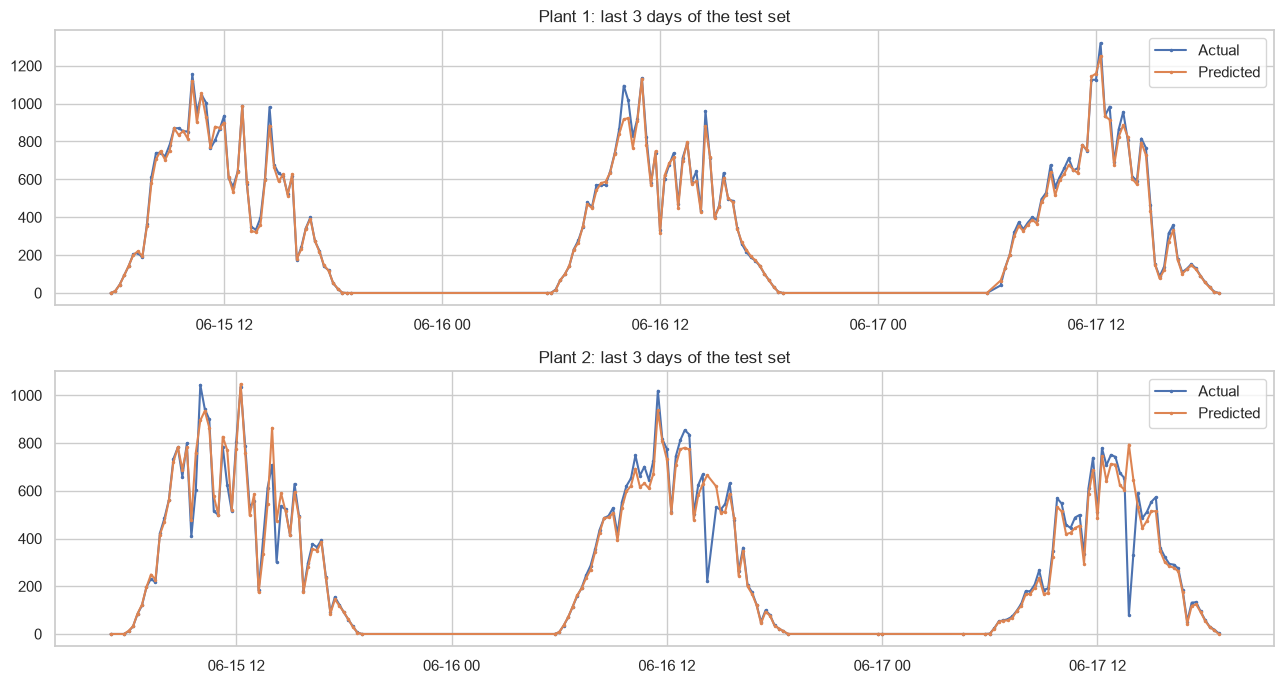

In [7]:
for p in (1, 2):
    s = test[test.PLANT == p]
    print(f"Plant {p}: MAE={mean_absolute_error(s[TARGET], s.PRED):.1f}  R2={r2_score(s[TARGET], s.PRED):.3f}")

fig, ax = plt.subplots(2, 1, figsize=(13, 7))
for a, p in zip(ax, (1, 2)):
    s = test[test.PLANT == p]
    s = s[s.DATE_TIME >= s.DATE_TIME.max().normalize() - pd.Timedelta(days=2)]
    a.plot(s.DATE_TIME, s[TARGET], ".-", label="Actual", ms=3)
    a.plot(s.DATE_TIME, s.PRED, ".-", label="Predicted", ms=3)
    a.set_title(f"Plant {p}: last 3 days of the test set"); a.legend()
plt.tight_layout(); plt.savefig(FIG/"test_timeseries.png", dpi=150); plt.show()

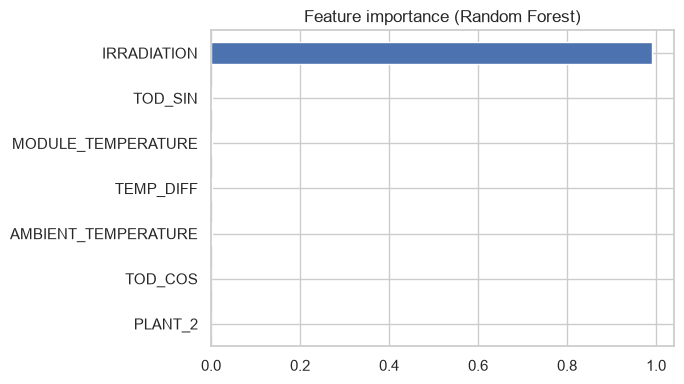

In [8]:
imp = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 4), title=f"Feature importance ({best_name})")
plt.tight_layout(); plt.savefig(FIG/"feature_importance.png", dpi=150); plt.show()

In [9]:
# Model used for evaluation (trained on train only)
joblib.dump(best_model, MODELS/"solar_model_eval.pkl")

# Deployment model: same settings, retrained on all available data
deploy_model = clone(best_model).fit(pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))
joblib.dump(deploy_model, MODELS/"solar_model.pkl")

pd.concat([results.assign(CV_MAE=np.nan), tuned_df]).to_csv("../reports/model_results.csv", index=False)

# Reload check
m = joblib.load(MODELS/"solar_model.pkl")
sample = pd.DataFrame([[0.8, 50, 32, 18, 0, -1, 0]], columns=FEATURES)   # about midday, high sun
print("Predicted avg AC power per inverter (kW):", m.predict(sample)[0].round(1))

Predicted avg AC power per inverter (kW): 1022.9
